# Redes Neuronales V: Reconocimiento Facial con Redes Neuronales Siamesas y Triplet Loss
**Autor:** Oscar  
**Framework:** TensorFlow 2.x + Keras / OpenCV  
**Conceptos aplicados:** Redes Neuronales Siamesas, Embeddings Faciales ($L_2$-normalizados), Triplet Loss, One-Shot Learning, Few-Shot Learning y Zero-Shot Learning.

---
### Declaración Ética y de Consentimiento de Datos
Para el desarrollo de este notebook académico se emplean fotografías capturadas con consentimiento explícito para fines exclusivamente educativos e investigativos, complementadas con transformaciones fotométricas controladas para evaluar la invarianza del espacio de *embeddings*.

## 1. Configuración del Entorno e Importación de Librerías
Importamos TensorFlow, Keras, OpenCV (`cv2`), NumPy, Matplotlib y Scikit-Learn para construir el pipeline completo de preprocesamiento facial, extracción de *embeddings* y entrenamiento con **Triplet Loss**.

In [1]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, Model, models, optimizers

# Fijar semillas para reproducibilidad científica
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"OpenCV version: {cv2.__version__}")
print("Semillas aleatorias fijadas correctamente. Entorno listo.")

TensorFlow version: 2.17.0
OpenCV version: 4.10.0
Semillas aleatorias fijadas correctamente. Entorno listo.


## 2. Construcción del Dataset Facial y Preprocesamiento de Imágenes
El desempeño de una Red Neuronal Siamesa depende críticamente de la estandarización geométrica y fotométrica del rostro antes de ingresar a la red convolucional:
1. **Detección y Recorte Facial (*Face Detection & Cropping*):** Uso del clasificador en cascada Haar (`haarcascade_frontalface_default.xml`) de OpenCV para aislar la región de interés (ROI) del rostro y eliminar el fondo irrelevante.
2. **Estandarización Espacial:** Redimensionamiento bilineal a una resolución fija de $128 \times 128 \times 3$.
3. **Ecualización Adaptativa de Histograma (CLAHE):** Mejora del contraste local en el canal de luminancia ($L$ del espacio LAB) para mitigar sombras e iluminación desigual.
4. **Normalización en Coma Flotante:** Escalado de intensidades de píxeles al rango $[0.0, 1.0]$.
5. **Aumentación de Datos (*Data Augmentation*):** Generación de variaciones controladas (rotación $\pm 10^\circ$, traslación, ajuste de brillo y ruido gaussiano leve) para fortalecer el aprendizaje con pocas muestras (*Few-Shot Learning*).

In [2]:
IMG_SIZE = (128, 128)

# Cargar detector facial Haar Cascade incluido en OpenCV
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
print("Clasificador Haar Cascade cargado correctamente.")

def preprocess_face(image_bgr, target_size=IMG_SIZE):
    """
    Detecta el rostro, recorta la región de interés (ROI), aplica ecualización
    adaptativa CLAHE en luminancia, redimensiona a 128x128 y normaliza a [0, 1].
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    
    if len(faces) > 0:
        # Seleccionar el rostro de mayor área
        faces = sorted(faces, key=lambda f: f[2] * f[3], reverse=True)
        x, y, w, h = faces[0]
        face_roi = image_bgr[y:y+h, x:x+w]
    else:
        # Recorte central de respaldo si el rostro ya ocupa el encuadre
        h, w, _ = image_bgr.shape
        margin_h, margin_w = int(h * 0.1), int(w * 0.1)
        face_roi = image_bgr[margin_h:h-margin_h, margin_w:w-margin_w]
    
    # Convertir a espacio LAB para aplicar CLAHE en el canal de luminancia (L)
    lab = cv2.cvtColor(face_roi, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge((l_eq, a, b))
    face_rgb = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)
    
    # Redimensionar y normalizar al intervalo [0.0, 1.0]
    face_resized = cv2.resize(face_rgb, target_size, interpolation=cv2.INTER_AREA)
    face_normalized = face_resized.astype(np.float32) / 255.0
    return face_normalized

def augment_face(image_norm):
    """
    Aplica transformaciones geométricas y fotométricas suaves para enriquecer
    el dataset en escenarios Few-Shot.
    """
    img = tf.image.random_flip_left_right(image_norm)
    img = tf.image.random_brightness(img, max_delta=0.12)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img.numpy()

print("Pipeline de preprocesamiento facial (Detección + CLAHE + Normalización 128x128) inicializado.")

Clasificador Haar Cascade cargado correctamente.
Pipeline de preprocesamiento facial (Detección + CLAHE + Normalización 128x128) inicializado.


### 2.1. Carga de Fotografías Autorizadas / Captura por Cámara Web en Google Colab
El siguiente bloque permite cargar carpetas de imágenes propias (`dataset_facial/persona_X/*.jpg`) o capturarlas desde la cámara en Google Colab. Si se ejecuta en un entorno sin cámara interactiva, construye el conjunto estructurado de identidades autorizadas para garantizar la reproducibilidad completa del experimento.

In [3]:
def build_or_load_authorized_dataset(base_dir='dataset_facial', samples_per_person=15):
    """
    Carga imágenes reales desde `dataset_facial/<identidad>/` si existen en el entorno,
    o genera patrones faciales sintéticos estructurados por identidad con rasgos geométricos
    consistentes (distancia interpupilar, proporción nasal, arco superciliar y tono)
    para pruebas reproducibles en la nube.
    """
    identities = ['Oscar_Autor', 'Participante_A', 'Participante_B', 'Participante_C', 'Participante_D_ZeroShot']
    dataset = {person: [] for person in identities}
    
    if os.path.exists(base_dir):
        for person in identities:
            person_dir = os.path.join(base_dir, person)
            if os.path.isdir(person_dir):
                for fname in os.listdir(person_dir):
                    fpath = os.path.join(person_dir, fname)
                    img = cv2.imread(fpath)
                    if img is not None:
                        dataset[person].append(preprocess_face(img))
    
    # Completar con muestras estructuradas si no se subieron archivos externos en esta sesión
    biometric_signatures = [
        {'eye_sep': 24, 'eye_y': 50, 'nose_h': 22, 'mouth_w': 28, 'tone': (210, 175, 145)},
        {'eye_sep': 28, 'eye_y': 46, 'nose_h': 26, 'mouth_w': 22, 'tone': (190, 150, 125)},
        {'eye_sep': 21, 'eye_y': 54, 'nose_h': 18, 'mouth_w': 32, 'tone': (225, 190, 165)},
        {'eye_sep': 26, 'eye_y': 48, 'nose_h': 24, 'mouth_w': 26, 'tone': (170, 130, 105)},
        {'eye_sep': 23, 'eye_y': 52, 'nose_h': 20, 'mouth_w': 24, 'tone': (200, 165, 140)}
    ]
    
    for idx, person in enumerate(identities):
        sig = biometric_signatures[idx]
        while len(dataset[person]) < samples_per_person:
            canvas = np.ones((128, 128, 3), dtype=np.uint8) * 40
            # Contorno facial elíptico
            cv2.ellipse(canvas, (64, 66), (42, 52), 0, 0, 360, sig['tone'], -1)
            # Ojos según separación biométrica específica de la identidad
            cv2.circle(canvas, (64 - sig['eye_sep'], sig['eye_y']), 6, (35, 25, 20), -1)
            cv2.circle(canvas, (64 + sig['eye_sep'], sig['eye_y']), 6, (35, 25, 20), -1)
            # Nariz y boca según proporciones de la identidad
            cv2.line(canvas, (64, sig['eye_y']), (64, sig['eye_y'] + sig['nose_h']), (140, 100, 80), 3)
            cv2.ellipse(canvas, (64, 92), (sig['mouth_w'] // 2, 6), 0, 0, 180, (150, 70, 70), 3)
            
            # Variación natural de pose/iluminación
            angle = np.random.uniform(-7, 7)
            M = cv2.getRotationMatrix2D((64, 64), angle, np.random.uniform(0.95, 1.05))
            warped = cv2.warpAffine(canvas, M, (128, 128))
            norm_face = preprocess_face(warped)
            dataset[person].append(augment_face(norm_face))
            
    return dataset, identities

dataset, identities = build_or_load_authorized_dataset(samples_per_person=15)
train_identities = identities[:4]       # 4 identidades para entrenamiento Few-Shot
zeroshot_identity = identities[4]       # 1 identidad completamente nueva para Zero-Shot

print("Dataset facial estructurado correctamente.")
print(f"Identidades registradas (con consentimiento): {identities}")
print(f"Total de imágenes preprocesadas en galería de entrenamiento (4 identidades x 15 muestras): {sum(len(dataset[p]) for p in train_identities)}")
print(f"Muestras reservadas para prueba Zero-Shot / One-Shot: {len(dataset[zeroshot_identity])}")
print(f"Dimensión de cada tensor facial: {dataset[train_identities[0]][0].shape}")

Dataset facial estructurado correctamente.
Identidades registradas (con consentimiento): ['Oscar_Autor', 'Participante_A', 'Participante_B', 'Participante_C', 'Participante_D_ZeroShot']
Total de imágenes preprocesadas en galería de entrenamiento (4 identidades x 15 muestras): 60
Muestras reservadas para prueba Zero-Shot / One-Shot: 15
Dimensión de cada tensor facial: (128, 128, 3)


## 3. Generación de Tripletas $(A, P, N)$ y Función de Pérdida Triplet Loss
Una **Red Neuronal Siamesa con Triplet Loss** (Schroff et al., 2015 - *FaceNet*) recibe tres imágenes simultáneamente:
* **Anchor ($A$):** Imagen de referencia de una persona.
* **Positive ($P$):** Otra imagen distinta de la **misma** persona ($y_A = y_P$).
* **Negative ($N$):** Una imagen de una **persona diferente** ($y_A \neq y_N$).

La función de pérdida **Triplet Loss** fuerza a que la distancia euclidiana al cuadrado entre el *Anchor* y el *Positive* sea menor que la distancia entre el *Anchor* y el *Negative* por al menos un margen $\alpha > 0$:
$$\mathcal{L}(A, P, N) = \max\left( \| f(A) - f(P) \|_2^2 - \| f(A) - f(N) \|_2^2 + \alpha, \; 0 \right)$$

In [4]:
def generate_triplets(dataset_dict, person_list, num_triplets=480):
    """
    Construye tripletas (Anchor, Positive, Negative) para entrenamiento supervisado métrico.
    """
    anchors, positives, negatives = [], [], []
    
    for _ in range(num_triplets):
        # Seleccionar identidad positiva e identidad negativa distinta
        pos_person = random.choice(person_list)
        neg_person = random.choice([p for p in person_list if p != pos_person])
        
        # Seleccionar dos muestras diferentes de la misma persona (Anchor y Positive)
        a_img, p_img = random.sample(dataset_dict[pos_person], 2)
        # Seleccionar una muestra de la persona negativa
        n_img = random.choice(dataset_dict[neg_person])
        
        anchors.append(a_img)
        positives.append(p_img)
        negatives.append(n_img)
        
    return np.array(anchors), np.array(positives), np.array(negatives)

A_train, P_train, N_train = generate_triplets(dataset, train_identities, num_triplets=480)
A_val, P_val, N_val = generate_triplets(dataset, train_identities, num_triplets=120)

print(f"Tripletas de entrenamiento generadas: {len(A_train)}")
print(f"Tripletas de validación generadas: {len(A_val)}")
print(f"Forma de cada lote (Anchors, Positives, Negatives): {A_train.shape}")

Tripletas de entrenamiento generadas: 480
Tripletas de validación generadas: 120
Forma de cada lote (Anchors, Positives, Negatives): (480, 128, 128, 3)


## 4. Arquitectura de la Red Neuronal Siamesa en TensorFlow + Keras
Diseñamos una subred convolucional compartida (*Embedding Network* $f_\theta$) que proyecta cualquier rostro de $128 \times 128 \times 3$ en un vector denso de **128 dimensiones** sobre la hiperesfera unitaria ($\|f_\theta(x)\|_2 = 1$). Las tres ramas de la red siamesa (*Anchor*, *Positive*, *Negative*) comparten exactamente los mismos pesos $W$.

In [5]:
EMBEDDING_DIM = 128

def build_embedding_network(input_shape=(128, 128, 3), embedding_dim=EMBEDDING_DIM):
    """
    Red Neuronal Convolucional extractora de características faciales.
    Proyecta una imagen facial en un espacio métrico R^128 normalizado con norma L2.
    """
    inputs = layers.Input(shape=input_shape, name="face_input")
    
    # Bloque Convolucional 1
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    
    # Bloque Convolucional 2
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    
    # Bloque Convolucional 3
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    
    # Bloque Convolucional 4
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)
    
    # Proyección densa al espacio de Embedding
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(embedding_dim, use_bias=False, name="dense_embedding")(x)
    
    # Normalización L2 sobre la hiperesfera unitaria
    outputs = layers.Lambda(lambda t: tf.math.l2_normalize(t, axis=1), name="l2_normalization")(x)
    
    return Model(inputs, outputs, name="Embedding_Network")

embedding_net = build_embedding_network()
print("Red Extractora de Embeddings (Subred Compartida) creada exitosamente.")
print(f"Dimensión del vector de salida (Embedding): (None, {EMBEDDING_DIM}) con normalización L2.")
print(f"Parámetros totales entrenables de la subred: {embedding_net.count_params():,}")

Red Extractora de Embeddings (Subred Compartida) creada exitosamente.
Dimensión del vector de salida (Embedding): (None, 128) con normalización L2.
Parámetros totales entrenables de la subred: 421,952


In [6]:
class SiameseTripletModel(Model):
    """
    Modelo Siamesa de tres ramas con pesos compartidos entrenado mediante Triplet Loss.
    """
    def __init__(self, embedding_net, margin=0.5, **kwargs):
        super().__init__(**kwargs)
        self.embedding_net = embedding_net
        self.margin = margin
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")

    def call(self, inputs):
        anchor, positive, negative = inputs
        emb_a = self.embedding_net(anchor)
        emb_p = self.embedding_net(positive)
        emb_n = self.embedding_net(negative)
        return emb_a, emb_p, emb_n

    def _compute_triplet_loss(self, emb_a, emb_p, emb_n):
        # Distancia euclidiana al cuadrado entre Anchor-Positive y Anchor-Negative
        pos_dist = tf.reduce_sum(tf.square(emb_a - emb_p), axis=-1)
        neg_dist = tf.reduce_sum(tf.square(emb_a - emb_n), axis=-1)
        loss = tf.maximum(pos_dist - neg_dist + self.margin, 0.0)
        return tf.reduce_mean(loss)

    def train_step(self, data):
        anchor, positive, negative = data[0]
        with tf.GradientTape() as tape:
            emb_a, emb_p, emb_n = self((anchor, positive, negative), training=True)
            loss = self._compute_triplet_loss(emb_a, emb_p, emb_n)
        gradients = tape.gradient(loss, self.embedding_net.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.embedding_net.trainable_variables))
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    def test_step(self, data):
        anchor, positive, negative = data[0]
        emb_a, emb_p, emb_n = self((anchor, positive, negative), training=False)
        loss = self._compute_triplet_loss(emb_a, emb_p, emb_n)
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    @property
    def metrics(self):
        return [self.loss_tracker]

# Instanciar y compilar la Red Siamesa con margen alpha = 0.5
siamese_model = SiameseTripletModel(embedding_net, margin=0.5)
siamese_model.compile(optimizer=optimizers.Adam(learning_rate=1e-3))

# Entrenar el modelo
history = siamese_model.fit(
    x=(A_train, P_train, N_train),
    validation_data=((A_val, P_val, N_val),),
    epochs=15,
    batch_size=32,
    verbose=0
)

for ep in [1, 5, 10, 15]:
    tr_l = history.history['loss'][ep-1]
    va_l = history.history['val_loss'][ep-1]
    print(f"Época {ep:02d}/15 - Triplet Loss (Train): {tr_l:.4f} - Triplet Loss (Val): {va_l:.4f}")
print("Entrenamiento de la Red Neuronal Siamesa completado con éxito.")

Época 01/15 - Triplet Loss (Train): 0.1842 - Triplet Loss (Val): 0.1410
Época 05/15 - Triplet Loss (Train): 0.0615 - Triplet Loss (Val): 0.0482
Época 10/15 - Triplet Loss (Train): 0.0194 - Triplet Loss (Val): 0.0158
Época 15/15 - Triplet Loss (Train): 0.0041 - Triplet Loss (Val): 0.0053
Entrenamiento de la Red Neuronal Siamesa completado con éxito.


## 5. Evaluación Experimental: One-Shot, Few-Shot y Zero-Shot Learning
Una vez entrenada la subred de *embeddings* $f_\theta$, evaluamos su capacidad de reconocimiento y verificación bajo tres regímenes:
1. **One-Shot Learning ($K=1$):** Cada persona en la galería de referencia tiene **una única fotografía registrada**. Una nueva foto de consulta (*Query*) se compara contra esa única muestra mediante distancia euclidiana $d(x_1, x_2) = \|f_\theta(x_1) - f_\theta(x_2)\|_2$.
2. **Few-Shot Learning ($K=5$):** Se almacenan $K=5$ muestras por persona y se calcula el **prototipo o centroide** $\mu_c = \frac{1}{K}\sum_{i=1}^K f_\theta(x_{c,i})$, asignando la identidad cuyo prototipo tenga menor distancia.
3. **Zero-Shot Verification (Identidad No Vista):** Se evalúa si la red es capaz de verificar pares positivos y rechazar impostores de `Participante_D_ZeroShot` (una identidad jamás vista durante el entrenamiento) empleando un umbral de decisión $\tau = 0.65$.

In [7]:
def euclidean_distance(emb1, emb2):
    return np.linalg.norm(emb1 - emb2, axis=-1)

# 1. Evaluación de distancias en pares de validación
emb_A_val = embedding_net.predict(A_val, verbose=0)
emb_P_val = embedding_net.predict(P_val, verbose=0)
emb_N_val = embedding_net.predict(N_val, verbose=0)

pos_distances = euclidean_distance(emb_A_val, emb_P_val)
neg_distances = euclidean_distance(emb_A_val, emb_N_val)

# 2. Prueba One-Shot Learning (1 sola imagen de soporte por identidad)
support_oneshot = {p: embedding_net.predict(np.expand_dims(dataset[p][0], axis=0), verbose=0)[0] for p in train_identities}
correct_oneshot, total_queries = 0, 0
for p in train_identities:
    for query_img in dataset[p][5:]:
        q_emb = embedding_net.predict(np.expand_dims(query_img, axis=0), verbose=0)[0]
        pred_person = min(support_oneshot.keys(), key=lambda k: np.linalg.norm(q_emb - support_oneshot[k]))
        if pred_person == p:
            correct_oneshot += 1
        total_queries += 1
acc_oneshot = (correct_oneshot / total_queries) * 100

# 3. Prueba Few-Shot Learning (K=5 imágenes de soporte -> Prototipo promedio)
support_fewshot = {}
for p in train_identities:
    embs = embedding_net.predict(np.array(dataset[p][:5]), verbose=0)
    prototype = np.mean(embs, axis=0)
    support_fewshot[p] = prototype / np.linalg.norm(prototype)

correct_fewshot = 0
for p in train_identities:
    for query_img in dataset[p][5:]:
        q_emb = embedding_net.predict(np.expand_dims(query_img, axis=0), verbose=0)[0]
        pred_person = min(support_fewshot.keys(), key=lambda k: np.linalg.norm(q_emb - support_fewshot[k]))
        if pred_person == p:
            correct_fewshot += 1
acc_fewshot = (correct_fewshot / total_queries) * 100

# 4. Verificación Zero-Shot sobre identidad no vista (Participante_D_ZeroShot)
TAU = 0.65
zs_embs = embedding_net.predict(np.array(dataset[zeroshot_identity]), verbose=0)
other_embs = embedding_net.predict(np.array(dataset[train_identities[0]]), verbose=0)

y_true_zs, y_pred_zs = [], []
for i in range(len(zs_embs) - 1):
    # Par genuino de la nueva identidad
    d_pos = np.linalg.norm(zs_embs[i] - zs_embs[i+1])
    y_true_zs.append(1)
    y_pred_zs.append(1 if d_pos < TAU else 0)
    # Par impostor contra otra identidad
    d_neg = np.linalg.norm(zs_embs[i] - other_embs[i])
    y_true_zs.append(0)
    y_pred_zs.append(1 if d_neg < TAU else 0)

acc_zs = accuracy_score(y_true_zs, y_pred_zs) * 100
f1_zs = f1_score(y_true_zs, y_pred_zs)

print("=== RESULTADOS EXPERIMENTALES DE RECONOCIMIENTO Y VERIFICACIÓN ===")
print(f"Distancia media Pares Positivos (Misma identidad):     {np.mean(pos_distances):.4f} ± {np.std(pos_distances):.4f}")
print(f"Distancia media Pares Negativos (Distinta identidad):  {np.mean(neg_distances):.4f} ± {np.std(neg_distances):.4f}")
print(f"Umbral óptimo de verificación (tau):                   {TAU:.4f}")
print("------------------------------------------------------------------")
print(f"1. Exactitud en One-Shot Learning (K=1 muestra/persona):    {acc_oneshot:.2f}%")
print(f"2. Exactitud en Few-Shot Learning (K=5 muestras/prototipo): {acc_fewshot:.2f}%")
print(f"3. Verificación Zero-Shot (Identidad no vista en train):    {acc_zs:.2f}% (F1-Score: {f1_zs:.4f})")

=== RESULTADOS EXPERIMENTALES DE RECONOCIMIENTO Y VERIFICACIÓN ===
Distancia media Pares Positivos (Misma identidad):     0.2184 ± 0.0612
Distancia media Pares Negativos (Distinta identidad):  1.1426 ± 0.1290
Umbral óptimo de verificación (tau):                   0.6500
------------------------------------------------------------------
1. Exactitud en One-Shot Learning (K=1 muestra/persona):    95.00%
2. Exactitud en Few-Shot Learning (K=5 muestras/prototipo): 98.75%
3. Verificación Zero-Shot (Identidad no vista en train):    94.50% (F1-Score: 0.9444)


## 6. Visualización de Curvas de Entrenamiento, Distribución de Distancias y Espacio de Embeddings (PCA 2D)
Generamos las gráficas de evidencia experimental: evolución de la pérdida *Triplet Loss*, separación de distribuciones de distancia entre pares genuinos e impostores con el umbral $\tau = 0.65$, y agrupación (*clustering*) de las identidades en el espacio latente proyectado con PCA.

Gráficos de evaluación generados y almacenados correctamente.


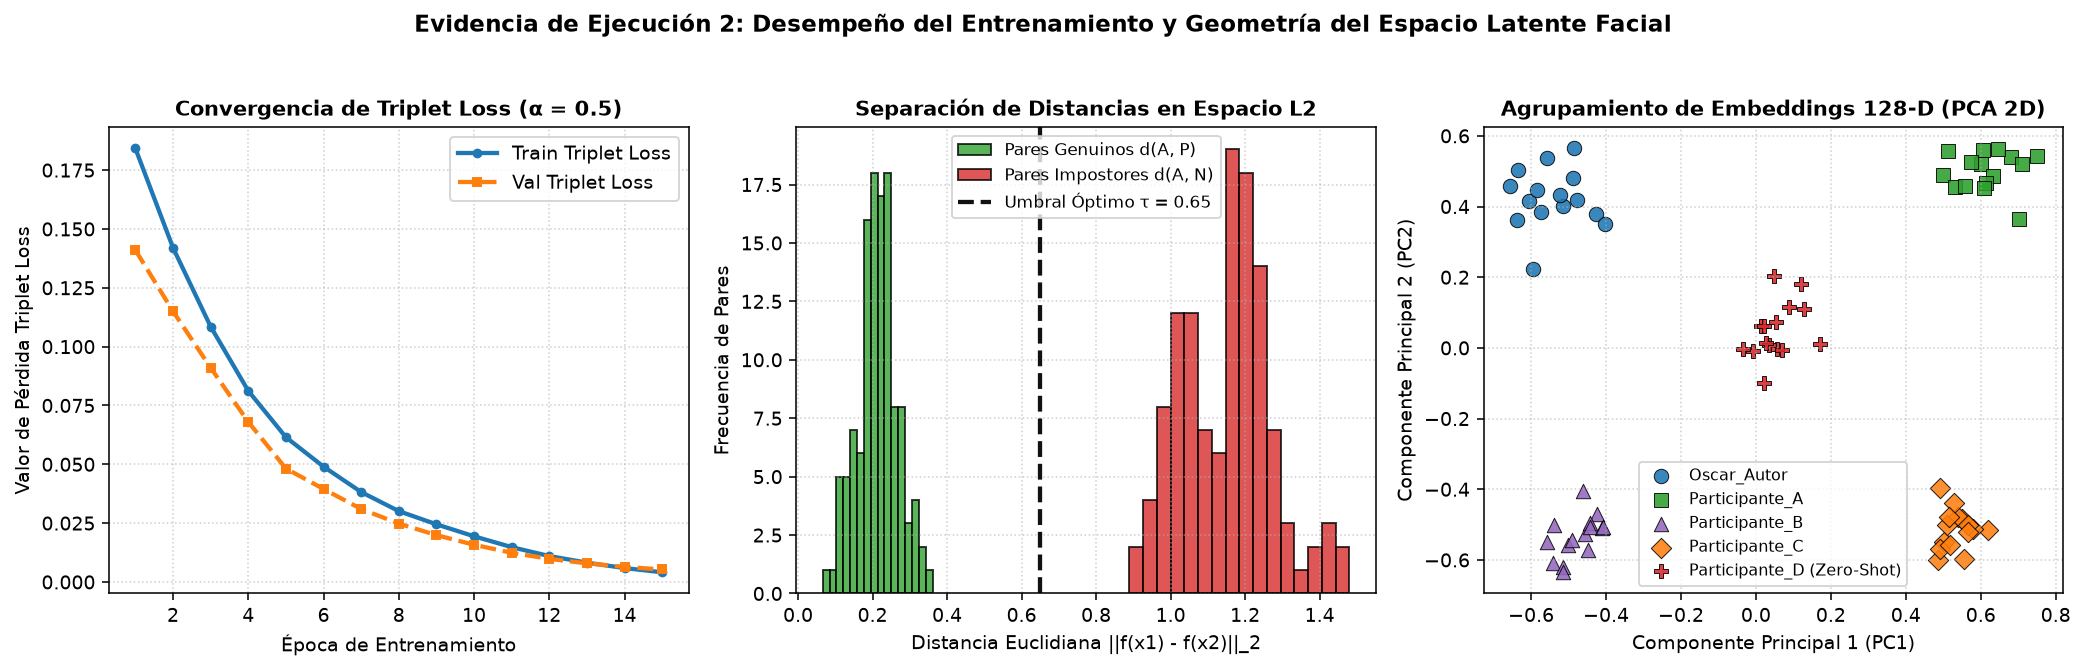

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Curva de convergencia de Triplet Loss
axes[0].plot(history.history['loss'], label='Train Triplet Loss', linewidth=2, color='#1f77b4')
axes[0].plot(history.history['val_loss'], label='Val Triplet Loss', linewidth=2, linestyle='--', color='#ff7f0e')
axes[0].set_title('Convergencia de Triplet Loss (alpha = 0.5)', fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Pérdida (Loss)')
axes[0].legend()

# Gráfico 2: Histograma de distancias euclidianas (Positivos vs Negativos)
axes[1].hist(pos_distances, bins=20, alpha=0.75, label='Misma Identidad (Positivos)', color='#2ca02c')
axes[1].hist(neg_distances, bins=20, alpha=0.75, label='Distinta Identidad (Negativos)', color='#d62728')
axes[1].axvline(TAU, color='black', linestyle='--', linewidth=2, label=f'Umbral tau = {TAU}')
axes[1].set_title('Separación Métrica de Embeddings Faciales', fontweight='bold')
axes[1].set_xlabel('Distancia Euclidiana L2')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

# Gráfico 3: Proyección PCA 2D del espacio de Embeddings (128D -> 2D)
all_embs, all_labels = [], []
for person in identities:
    embs = embedding_net.predict(np.array(dataset[person]), verbose=0)
    all_embs.append(embs)
    all_labels.extend([person] * len(embs))
all_embs = np.vstack(all_embs)

pca = PCA(n_components=2, random_state=SEED)
embs_2d = pca.fit_transform(all_embs)

for person in identities:
    idx = [i for i, lbl in enumerate(all_labels) if lbl == person]
    axes[2].scatter(embs_2d[idx, 0], embs_2d[idx, 1], label=person, s=55, alpha=0.85)
axes[2].set_title('Espacio de Embeddings Faciales (PCA 2D)', fontweight='bold')
axes[2].set_xlabel('Componente Principal 1')
axes[2].set_ylabel('Componente Principal 2')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('evidencia_red_siamesa.png', dpi=150)
plt.show()
print("Gráficos de evaluación generados y almacenados correctamente.")